# SAC / SAC+ISSR contingency tables (Poll-Schumann only)

Two skill-score exercises, both using the **Poll-Schumann (PS)** propulsion efficiency only
(no BADA 4.2), evaluated separately against **IAGOS** in-situ and **ERA5** reanalysis meteorology:

1. **SAC vs contrail formation** — predictor: $T_{\mathrm{amb}} < T_{\mathrm{LC}}$ (the
   Schmidt-Appleman criterion); truth: `contrail_formation`. This reproduces the
   Poll-Schumann half of Table 5 in `figure_6.ipynb`, without the uncertainty-corrected row.
2. **SAC + ISSR vs contrail persistence** — predictor: SAC **and** ice-supersaturation
   ($\mathrm{RH}_i \ge$ `ISSR_RHI_THRESHOLD`); truth: the annotated contrail survived longer
   than `PERSISTENCE_THRESHOLD_S` seconds (default 120 s, the end of the vortex phase used in
   `figure_7.ipynb`). Both thresholds are editable in the configuration cell, and the last
   sections sweep them so a trade-off value can be picked.

Contrail lifetimes come from `../data/landsat_sentinel_collocations_20260216_lifetimes_included.csv`
(column `lifetime` [s], written by `figure_7.ipynb`), which is populated for the annotated
Sentinel-2 cases only.

In [21]:
from typing import Union

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

from pycontrails.models.sac import T_critical_sac, T_sat_liquid_high_accuracy

from iagos_toolkit.weather.thermo import get_mixing_line_gradient_from_LHV

## Configuration

Everything tunable lives here.

In [22]:
CSV_PATH = "../data/landsat_sentinel_collocations_20260216_lifetimes_included.csv"

# A contrail counts as "persistent" when its annotated age exceeds this many seconds.
# 120 s = end of the vortex phase (see figure_7.ipynb). Sweep further down to trade off.
PERSISTENCE_THRESHOLD_S = 120.0
# PERSISTENCE_THRESHOLD_S = 300.0

# Ice-supersaturation threshold on RHi [-] used in the SAC + ISSR predictor.
ISSR_RHI_THRESHOLD = 1.0

# Lifetimes exist for Sentinel-2 annotations only, so the persistence exercise is
# Sentinel-only by default. Setting this to True adds the Landsat no-contrail cases as
# extra observed negatives (their contrail cases can never be scored, so this inflates
# the negative class - off by default).
INCLUDE_LANDSAT_NEGATIVES = False

# Rounding used in the printed tables / LaTeX rows.
DECIMALS = 3

## Load and filter

Same quality filters as `figure_6.ipynb`: valid IAGOS temperature and RH flags, a contrail
annotation decision, and a PS efficiency for both meteorology sources.

In [23]:
df = pd.read_csv(CSV_PATH, comment='#')

df = df[df["air_temperature_iagos_validity"] <= 0]
df = df[df["rhl_iagos_validity"] <= 0]
df = df[df["contrail_formation"].notna()]
df = df[df["efficiency_PS_IAGOS"].notna()]
df = df[df["efficiency_PS_ERA5"].notna()]

df["contrail_formation"] = df["contrail_formation"].astype(bool)

print("Number of collocations:", len(df))
print(df.groupby(["satellite", "contrail_formation"]).size())

Number of collocations: 543
satellite  contrail_formation
Landsat    False                  95
           True                   82
Sentinel   False                 171
           True                  195
dtype: int64


## SAC temperatures (Poll-Schumann)

In [24]:
def get_T_SAC(p: Union[float, np.ndarray],
              T: Union[float, np.ndarray],
              RH: Union[float, np.ndarray],
              **kwargs) -> np.ndarray:
    """
    Vectorized computation of T_SAC for given pressure, temperature, and RH.

    Parameters
    ----------
    p : float or np.ndarray
        Pressure in Pa
    T : float or np.ndarray
        Temperature in K
    RH : float or np.ndarray
        Relative humidity w.r.t water [0, 1]
    **kwargs :
        Additional parameters (e.g., eta)
    """
    p = np.atleast_1d(p)
    T = np.atleast_1d(T)
    RH = np.atleast_1d(RH)

    p, T, RH = np.broadcast_arrays(p, T, RH)

    G = get_mixing_line_gradient_from_LHV(p, **kwargs)
    T_LM = T_sat_liquid_high_accuracy(G)

    return T_critical_sac(T_LM, RH, G, maxiter=10)


df["T_SAC_PS_IAGOS"] = get_T_SAC(
    df["air_pressure"].values,
    df["air_temperature_iagos"].values,
    df["rhl_iagos"].values,
    eta=df["efficiency_PS_IAGOS"].values
)

df["T_SAC_PS_ERA5"] = get_T_SAC(
    df["air_pressure"].values,
    df["air_temperature_era5"].values,
    df["rhl_era5"].values,
    eta=df["efficiency_PS_ERA5"].values
)

df["delta_T_SAC_PS_IAGOS"] = df["air_temperature_iagos"] - df["T_SAC_PS_IAGOS"]
df["delta_T_SAC_PS_ERA5"] = df["air_temperature_era5"] - df["T_SAC_PS_ERA5"]

# SAC met: ambient temperature below the critical (Schmidt-Appleman) temperature.
df["SAC_PS_IAGOS"] = df["air_temperature_iagos"] < df["T_SAC_PS_IAGOS"]
df["SAC_PS_ERA5"] = df["air_temperature_era5"] < df["T_SAC_PS_ERA5"]

print(df[["SAC_PS_IAGOS", "SAC_PS_ERA5"]].sum())

SAC_PS_IAGOS    289
SAC_PS_ERA5     310
dtype: int64


## Scoring helpers

`contingency` returns the 2x2 table plus the standard skill scores. `ETS` (equitable threat
score) is kept for consistency with `figure_6.ipynb`; `F1` is added because it is the natural
single number to maximise when trading precision against recall.

In [25]:
def contingency(predicted, observed, label=None):
    """
    2x2 contingency table and skill scores for boolean predicted/observed arrays.

    Rows with a missing predictor or a missing truth value are dropped, and the number
    dropped is reported back in the ``dropped`` field.
    """
    predicted = pd.Series(predicted).reset_index(drop=True)
    observed = pd.Series(observed).reset_index(drop=True)

    valid = predicted.notna() & observed.notna()
    dropped = int((~valid).sum())

    p = predicted[valid].astype(bool).to_numpy()
    o = observed[valid].astype(bool).to_numpy()

    tp = int((p & o).sum())
    fp = int((p & ~o).sum())
    fn = int((~p & o).sum())
    tn = int((~p & ~o).sum())
    n = tp + fp + fn + tn

    precision = tp / (tp + fp) if (tp + fp) > 0 else float("nan")
    recall = tp / (tp + fn) if (tp + fn) > 0 else float("nan")
    f1 = (2 * precision * recall / (precision + recall)
          if (precision + recall) > 0 else float("nan"))
    accuracy = (tp + tn) / n if n > 0 else float("nan")

    random_hits = ((tp + fp) * (tp + fn)) / n if n > 0 else 0.0
    denom = tp + fp + fn - random_hits
    ets = (tp - random_hits) / denom if denom != 0 else float("nan")

    out = {
        "TP": tp, "FP": fp, "FN": fn, "TN": tn, "N": n,
        "precision": precision, "recall": recall, "F1": f1,
        "accuracy": accuracy, "ETS": ets, "dropped": dropped,
    }
    if label is not None:
        out = {"Case": label, **out}
    return out


def contingency_table(row):
    """Render one `contingency` result as a labelled 2x2 DataFrame."""
    return pd.DataFrame(
        [[row["TP"], row["FP"]], [row["FN"], row["TN"]]],
        index=pd.Index(["Predicted: yes", "Predicted: no"]),
        columns=pd.Index(["Observed: yes", "Observed: no"]),
    )


def issr_flag(rhi, threshold):
    """
    Ice-supersaturation flag, as a nullable boolean.

    Rows with a missing RHi become pd.NA so they propagate through the `&` with the SAC
    flag and are dropped by `contingency`, rather than being silently scored as negatives.
    """
    return (rhi >= threshold).astype("boolean").mask(rhi.isna())


def to_latex_rows(metrics_df, cols=None, title=""):
    """Print the metrics table as ampersand-separated LaTeX rows (figure_6.ipynb style)."""
    cols = cols or ["Case", "TP", "FP", "FN", "TN", "precision", "recall", "F1", "ETS"]
    print(f"{title}\n")
    print(" & ".join(cols) + " \\\\")
    for _, row in metrics_df[cols].iterrows():
        line = " & ".join(
            f"{val:.{DECIMALS}f}" if isinstance(val, float) else str(val)
            for val in row
        )
        print(line + " \\\\")

# 1. SAC vs contrail formation

Predictor: $T_{\mathrm{amb}} < T_{\mathrm{LC}}$ (PS efficiency). Truth: `contrail_formation`.
Reported per satellite and for both satellites combined.

In [26]:
formation_rows = []

groups = list(df.groupby("satellite")) + [("Landsat+Sentinel", df)]

for sat, group in groups:
    for met, sac_col in [("IAGOS", "SAC_PS_IAGOS"), ("ERA5", "SAC_PS_ERA5")]:
        row = contingency(group[sac_col], group["contrail_formation"])
        formation_rows.append({"Satellite": sat, "Met": met, **row})

formation_metrics = pd.DataFrame(formation_rows)
formation_metrics.round(DECIMALS)

,Satellite,Met,TP,FP,FN,TN,N,precision,recall,F1,accuracy,ETS,dropped
0,Landsat,IAGOS,78,11,4,84,177,0.876,0.951,0.912,0.915,0.710,0
1,Landsat,ERA5,80,15,2,80,177,0.842,0.976,0.904,0.904,0.679,0
2,Sentinel,IAGOS,192,8,3,163,366,0.960,0.985,0.972,0.970,0.886,0
3,Sentinel,ERA5,192,23,3,148,366,0.893,0.985,0.937,0.929,0.749,0
4,Landsat+Sentinel,IAGOS,270,19,7,247,543,0.934,0.975,0.954,0.952,0.825,0
5,Landsat+Sentinel,ERA5,272,38,5,228,543,0.877,0.982,0.927,0.921,0.726,0


In [27]:
# 2x2 tables for the combined sample
for met in ["IAGOS", "ERA5"]:
    row = formation_metrics[
        (formation_metrics["Satellite"] == "Landsat+Sentinel")
        & (formation_metrics["Met"] == met)
    ].iloc[0]
    print(f"SAC vs contrail formation - {met} (Landsat+Sentinel, N={row['N']})")
    print(contingency_table(row).to_string(), "\n")

SAC vs contrail formation - IAGOS (Landsat+Sentinel, N=543)
                Observed: yes  Observed: no
Predicted: yes            270            19
Predicted: no               7           247 

SAC vs contrail formation - ERA5 (Landsat+Sentinel, N=543)
                Observed: yes  Observed: no
Predicted: yes            272            38
Predicted: no               5           228 



In [28]:
fm = formation_metrics.copy()
fm["Case"] = fm["Satellite"] + " / " + fm["Met"]
to_latex_rows(fm, title="Poll-Schumann - SAC vs contrail formation:")

Poll-Schumann - SAC vs contrail formation:

Case & TP & FP & FN & TN & precision & recall & F1 & ETS \\
Landsat / IAGOS & 78 & 11 & 4 & 84 & 0.876 & 0.951 & 0.912 & 0.710 \\
Landsat / ERA5 & 80 & 15 & 2 & 80 & 0.842 & 0.976 & 0.904 & 0.679 \\
Sentinel / IAGOS & 192 & 8 & 3 & 163 & 0.960 & 0.985 & 0.972 & 0.886 \\
Sentinel / ERA5 & 192 & 23 & 3 & 148 & 0.893 & 0.985 & 0.937 & 0.749 \\
Landsat+Sentinel / IAGOS & 270 & 19 & 7 & 247 & 0.934 & 0.975 & 0.954 & 0.825 \\
Landsat+Sentinel / ERA5 & 272 & 38 & 5 & 228 & 0.877 & 0.982 & 0.927 & 0.726 \\


# 2. SAC + ISSR vs contrail persistence

**Predictor:** SAC met **and** $\mathrm{RH}_i \ge$ `ISSR_RHI_THRESHOLD`, using each
meteorology source consistently (IAGOS SAC with `rhi_iagos`, ERA5 SAC with `rhi_era5`), both
evaluated at the satellite sensing time.

**Truth:** `lifetime > PERSISTENCE_THRESHOLD_S`, where `lifetime` is the annotated contrail
age (contrail length / ground speed). Cases with no contrail (`contrail_formation == False`)
are observed negatives — nothing formed, so nothing persisted. Cases where a contrail formed
but no lifetime is available cannot be scored and are dropped.

Two deliberate choices worth knowing about:

- RHi is taken at the **satellite sensing time** (`rhi_iagos` / `rhi_era5`), not at the oldest
  annotated contrail point (`rhi_iagos_oldest`). The oldest-point values exist only for cases
  where a contrail was annotated, i.e. only for the positive class, so using them would make
  the predictor unavailable for every observed negative.
- Because lifetimes exist only for Sentinel-2 annotations, the default sample is Sentinel-2
  only (`INCLUDE_LANDSAT_NEGATIVES = False`).

A handful of rows have no `rhi_iagos` — these are warm (T > 273 K) low-altitude points where
RHi is undefined. The ISSR flag is nullable there, so `SAC and ISSR` only becomes unknown (and
gets dropped) if SAC is *also* met; where SAC is not met the prediction is a well-defined "no"
and the case is still scored. The `dropped` column reports how many actually fell out.

In [29]:
persistence = df if INCLUDE_LANDSAT_NEGATIVES else df[df["satellite"] == "Sentinel"]
persistence = persistence.copy()

# Scorable: either no contrail formed (observed negative), or a contrail formed and its
# annotated lifetime is known.
scorable = (~persistence["contrail_formation"]) | persistence["lifetime"].notna()
unscorable = int((~scorable).sum())
persistence = persistence[scorable]

persistence["contrail_persistence"] = (
    persistence["lifetime"].fillna(0.0) > PERSISTENCE_THRESHOLD_S
)

persistence["ISSR_IAGOS"] = issr_flag(persistence["rhi_iagos"], ISSR_RHI_THRESHOLD)
persistence["ISSR_ERA5"] = issr_flag(persistence["rhi_era5"], ISSR_RHI_THRESHOLD)

persistence["SAC_ISSR_IAGOS"] = (
    persistence["SAC_PS_IAGOS"].astype("boolean") & persistence["ISSR_IAGOS"]
)
persistence["SAC_ISSR_ERA5"] = (
    persistence["SAC_PS_ERA5"].astype("boolean") & persistence["ISSR_ERA5"]
)

print(f"Sample: {'Sentinel + Landsat negatives' if INCLUDE_LANDSAT_NEGATIVES else 'Sentinel-2 only'}")
print(f"Scorable cases: {len(persistence)} "
      f"(dropped {unscorable} contrail cases without an annotated lifetime)")
print(f"Observed persistent (> {PERSISTENCE_THRESHOLD_S:g} s): "
      f"{int(persistence['contrail_persistence'].sum())}")
print(f"Observed non-persistent: {int((~persistence['contrail_persistence']).sum())}")
print(f"Annotated contrails with a zero lifetime (always observed non-persistent): "
      f"{int((persistence['lifetime'] == 0).sum())}")
print(f"Missing RHi (undefined at T > 273 K) - "
      f"IAGOS: {int(persistence['rhi_iagos'].isna().sum())}, "
      f"ERA5: {int(persistence['rhi_era5'].isna().sum())}")
print(f"  of which the prediction is genuinely unknown (SAC also met, so dropped) - "
      f"IAGOS: {int(persistence['SAC_ISSR_IAGOS'].isna().sum())}, "
      f"ERA5: {int(persistence['SAC_ISSR_ERA5'].isna().sum())}")

Sample: Sentinel-2 only
Scorable cases: 366 (dropped 0 contrail cases without an annotated lifetime)
Observed persistent (> 120 s): 17
Observed non-persistent: 349
Annotated contrails with a zero lifetime (always observed non-persistent): 12
Missing RHi (undefined at T > 273 K) - IAGOS: 12, ERA5: 0
  of which the prediction is genuinely unknown (SAC also met, so dropped) - IAGOS: 0, ERA5: 0


In [30]:
persistence_rows = []
for met, pred_col in [("IAGOS", "SAC_ISSR_IAGOS"), ("ERA5", "SAC_ISSR_ERA5")]:
    row = contingency(persistence[pred_col], persistence["contrail_persistence"])
    persistence_rows.append({"Met": met, **row})

persistence_metrics = pd.DataFrame(persistence_rows)
persistence_metrics.round(DECIMALS)

,Met,TP,FP,FN,TN,N,precision,recall,F1,accuracy,ETS,dropped
0,IAGOS,10,24,7,325,366,0.294,0.588,0.392,0.915,0.214,0
1,ERA5,9,16,8,333,366,0.360,0.529,0.429,0.934,0.246,0


In [31]:
for _, row in persistence_metrics.iterrows():
    print(f"SAC + ISSR vs persistence (> {PERSISTENCE_THRESHOLD_S:g} s) - "
          f"{row['Met']} (N={row['N']})")
    print(contingency_table(row).to_string(), "\n")

SAC + ISSR vs persistence (> 120 s) - IAGOS (N=366)
                Observed: yes  Observed: no
Predicted: yes             10            24
Predicted: no               7           325 

SAC + ISSR vs persistence (> 120 s) - ERA5 (N=366)
                Observed: yes  Observed: no
Predicted: yes              9            16
Predicted: no               8           333 



In [32]:
pm = persistence_metrics.rename(columns={"Met": "Case"})
to_latex_rows(
    pm,
    title=(f"Poll-Schumann - SAC + ISSR (RHi >= {ISSR_RHI_THRESHOLD:g}) vs contrail "
           f"persistence (> {PERSISTENCE_THRESHOLD_S:g} s):"),
)

Poll-Schumann - SAC + ISSR (RHi >= 1) vs contrail persistence (> 120 s):

Case & TP & FP & FN & TN & precision & recall & F1 & ETS \\
IAGOS & 10 & 24 & 7 & 325 & 0.294 & 0.588 & 0.392 & 0.214 \\
ERA5 & 9 & 16 & 8 & 333 & 0.360 & 0.529 & 0.429 & 0.246 \\


## Contingency matrices at a glance

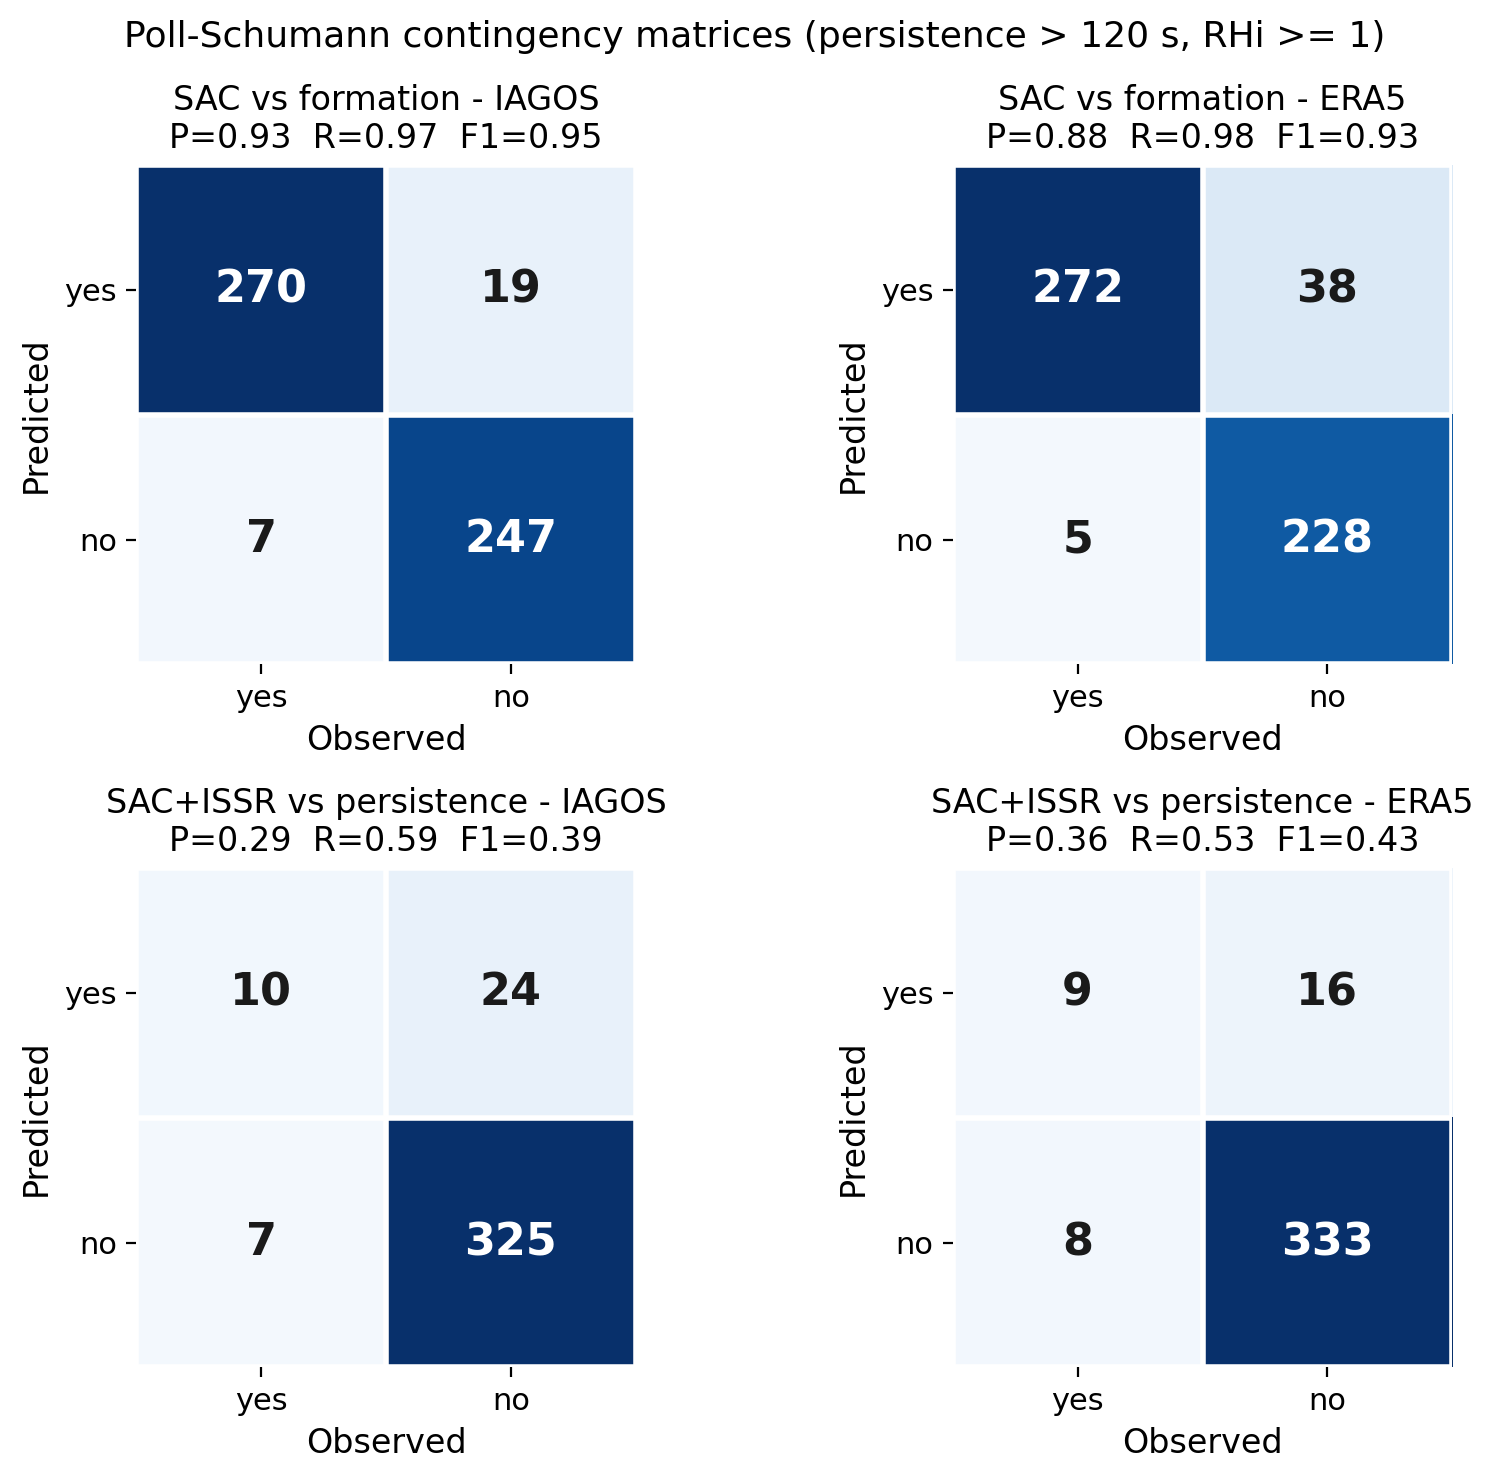

In [33]:
plt.rcParams.update({
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

panels = [
    ("SAC vs formation - IAGOS",
     formation_metrics[(formation_metrics["Satellite"] == "Landsat+Sentinel")
                       & (formation_metrics["Met"] == "IAGOS")].iloc[0]),
    ("SAC vs formation - ERA5",
     formation_metrics[(formation_metrics["Satellite"] == "Landsat+Sentinel")
                       & (formation_metrics["Met"] == "ERA5")].iloc[0]),
    ("SAC+ISSR vs persistence - IAGOS",
     persistence_metrics[persistence_metrics["Met"] == "IAGOS"].iloc[0]),
    ("SAC+ISSR vs persistence - ERA5",
     persistence_metrics[persistence_metrics["Met"] == "ERA5"].iloc[0]),
]

fig, axes = plt.subplots(2, 2, figsize=(8.5, 7.5), dpi=200)

for ax, (title, row) in zip(axes.ravel(), panels):
    counts = contingency_table(row).to_numpy()
    vmax = counts.max()

    ax.imshow(counts, cmap="Blues", vmin=0, vmax=vmax)

    for i in range(2):
        for j in range(2):
            ax.text(
                j, i, f"{counts[i, j]}",
                ha="center", va="center", fontsize=16, fontweight="bold",
                color="white" if counts[i, j] > 0.55 * vmax else "#1a1a1a",
            )

    ax.set_xticks([0, 1], ["yes", "no"])
    ax.set_yticks([0, 1], ["yes", "no"])
    ax.set_xlabel("Observed")
    ax.set_ylabel("Predicted")
    ax.set_title(
        f"{title}\nP={row['precision']:.2f}  R={row['recall']:.2f}  F1={row['F1']:.2f}",
        fontsize=12,
    )
    ax.set_xticks(np.arange(-0.5, 2, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 2, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.tick_params(which="minor", length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)

fig.suptitle(
    f"Poll-Schumann contingency matrices "
    f"(persistence > {PERSISTENCE_THRESHOLD_S:g} s, RHi >= {ISSR_RHI_THRESHOLD:g})",
    fontsize=13,
)
fig.tight_layout()
plt.show()

# 3. Trade-off: persistence threshold sweep

Precision, recall and F1 as a function of the lifetime cut-off that defines "persistent",
with the ISSR threshold held at `ISSR_RHI_THRESHOLD`. The dashed markers at 10 s and 120 s are
the end of the jet and vortex phases used in `figure_7.ipynb`.

**Read this sweep as a diagnostic, not an optimisation.** The predictor is fixed along the
sweep; only the definition of the truth moves, so the positive class shrinks as the threshold
rises and the scores are computed against a different target at every point. The threshold
that maximises F1 is therefore *where SAC + ISSR happens to line up best with the observed
lifetimes*, not a physically preferred definition of persistence — pick a cut-off you can
defend physically (e.g. surviving the vortex phase at 120 s) and read the cost off the curve.

In [34]:
def sweep_persistence_threshold(thresholds, issr_threshold=None):
    """Metrics vs the lifetime cut-off that defines observed persistence."""
    issr_threshold = ISSR_RHI_THRESHOLD if issr_threshold is None else issr_threshold

    predictors = {
        met: persistence[sac_col].astype("boolean") & issr_flag(persistence[rhi_col],
                                                                issr_threshold)
        for met, sac_col, rhi_col in [("IAGOS", "SAC_PS_IAGOS", "rhi_iagos"),
                                      ("ERA5", "SAC_PS_ERA5", "rhi_era5")]
    }

    rows = []
    for thr in thresholds:
        observed = persistence["lifetime"].fillna(0.0) > thr
        for met, pred in predictors.items():
            rows.append({
                "threshold_s": thr,
                "Met": met,
                "N_persistent": int(observed.sum()),
                **contingency(pred, observed),
            })
    return pd.DataFrame(rows)


thresholds = np.arange(0.0, 401.0, 5.0)
sweep = sweep_persistence_threshold(thresholds)
sweep.head()

,threshold_s,Met,N_persistent,TP,FP,FN,TN,N,precision,recall,F1,accuracy,ETS,dropped
0,0.0,IAGOS,183,34,0,149,183,366,1.000000,0.185792,0.313364,0.592896,0.102410,0
1,0.0,ERA5,183,25,0,158,183,366,1.000000,0.136612,0.240385,0.568306,0.073314,0
2,5.0,IAGOS,129,34,0,95,237,366,1.000000,0.263566,0.417178,0.740437,0.188148,0
3,5.0,ERA5,129,25,0,104,237,366,1.000000,0.193798,0.324675,0.715847,0.134693,0
4,10.0,IAGOS,94,33,1,61,271,366,0.970588,0.351064,0.515625,0.830601,0.281307,0


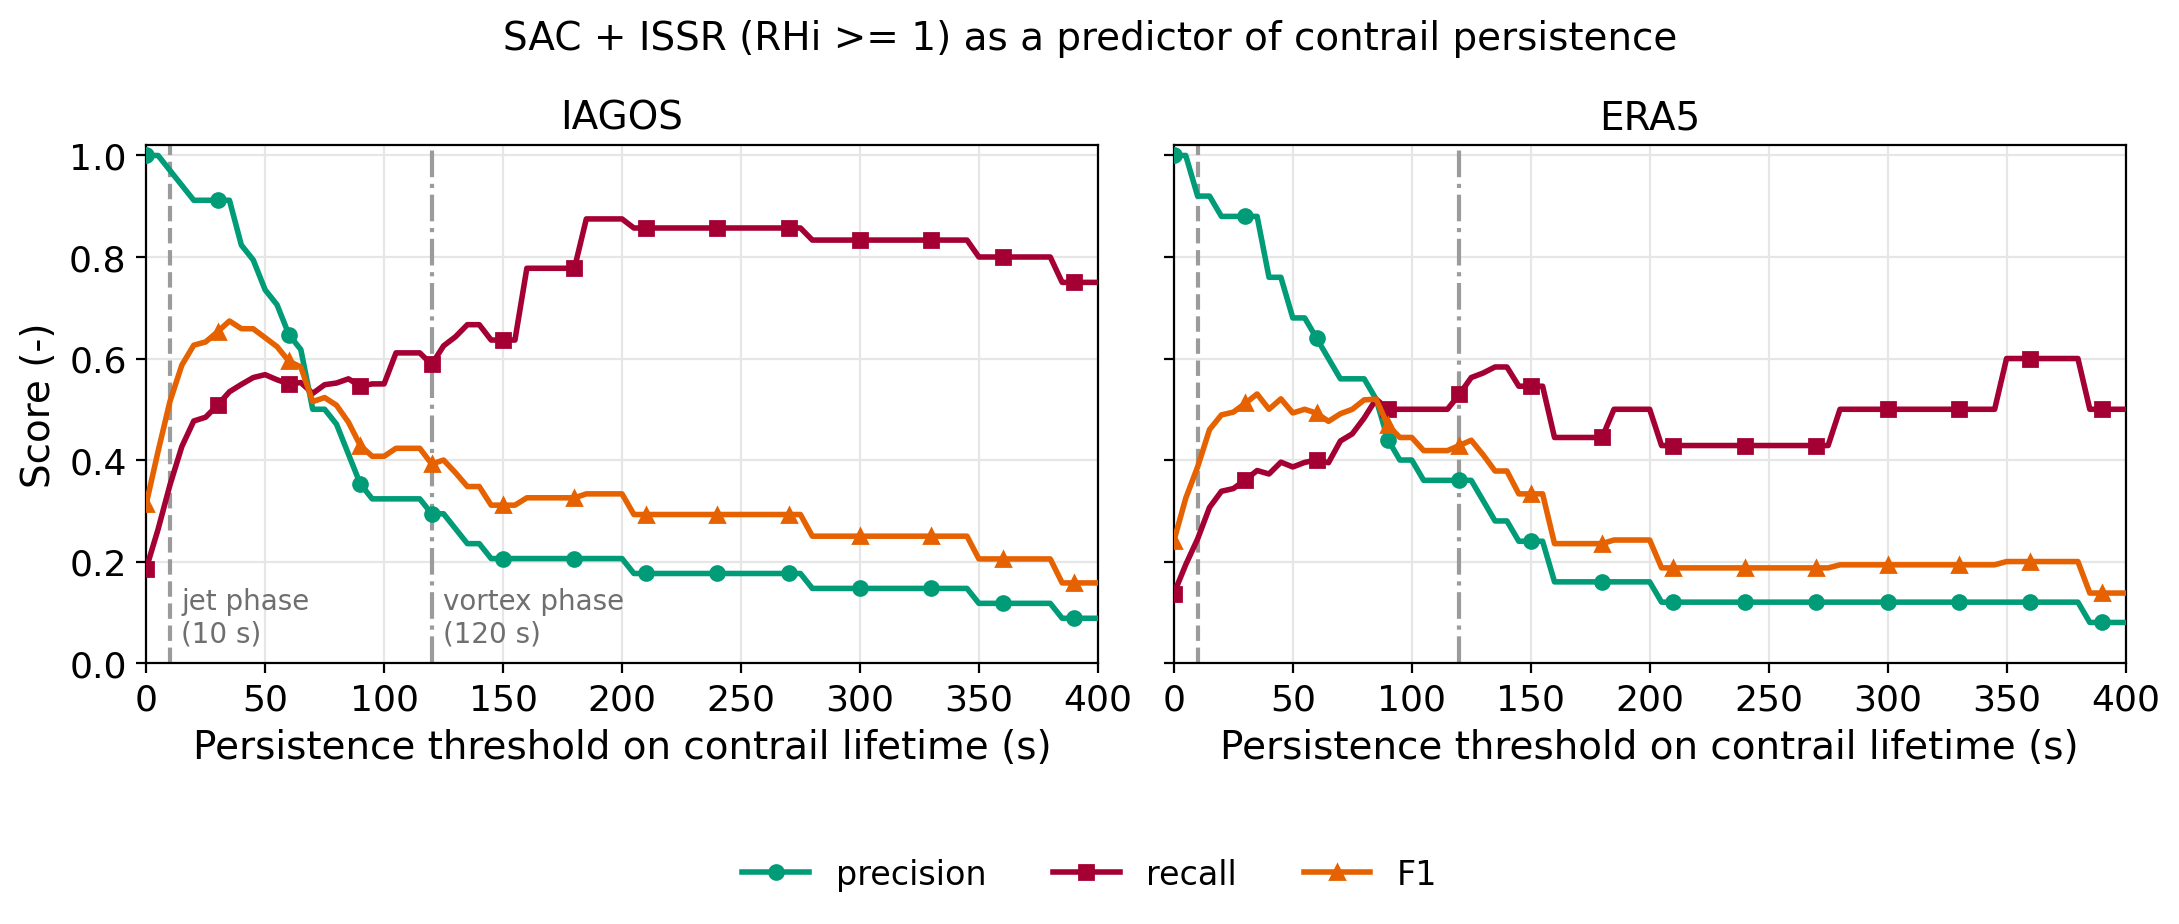

In [35]:
# Repo palette (figure_6 / figure_7): green / dark red / orange, validated for CVD separation.
metric_style = {
    "precision": ("#009b77", "o"),
    "recall":    ("#a50034", "s"),
    "F1":        ("#E66100", "^"),
}

plt.rcParams.update({
    "axes.titlesize": 14,
    "axes.labelsize": 14,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 12,
})

def plot_sweep(sweep_df, x_col, x_label, suptitle, ref_lines=(), markevery=6):
    """
    Precision / recall / F1 vs a swept threshold, one panel per meteorology source.

    `ref_lines` is a list of (x, linestyle, label) reference markers; labels are drawn
    along the bottom of the left panel so they never collide with the curves.
    """
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True, dpi=200)
    x = sweep_df[x_col]

    for ax, met in zip(axes, ["IAGOS", "ERA5"]):
        sub = sweep_df[sweep_df["Met"] == met].sort_values(x_col)

        for xpos, linestyle, _ in ref_lines:
            ax.axvline(xpos, linestyle=linestyle, color="#9b9b9b", linewidth=1.5, zorder=1)

        for metric, (color, marker) in metric_style.items():
            ax.plot(
                sub[x_col], sub[metric],
                color=color, linewidth=2, marker=marker, markersize=5, markevery=markevery,
                label=metric, zorder=3,
            )

        ax.set_xlabel(x_label)
        ax.set_title(met)
        ax.set_ylim(0, 1.02)
        ax.set_xlim(x.min(), x.max())
        ax.grid(True, color="#e6e6e6", linewidth=0.8)
        ax.set_axisbelow(True)

    axes[0].set_ylabel("Score (-)")

    span = x.max() - x.min()
    for xpos, _, label in ref_lines:
        if label:
            axes[0].text(xpos + 0.012 * span, 0.03, label,
                         fontsize=10, color="#6f6f6f", va="bottom", ha="left")

    handles, labels = axes[0].get_legend_handles_labels()
    fig.suptitle(suptitle, fontsize=14)
    fig.tight_layout()
    fig.subplots_adjust(bottom=0.28)
    fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False,
               bbox_to_anchor=(0.5, 0.0))
    plt.show()


# 10 s / 120 s are the end of the jet and vortex phases (figure_7.ipynb); the configured
# threshold is added as a solid marker when it is not already one of those.
ref_lines = [(10, "--", "jet phase\n(10 s)"), (120, "-.", "vortex phase\n(120 s)")]
if PERSISTENCE_THRESHOLD_S not in (10, 120):
    ref_lines.append((PERSISTENCE_THRESHOLD_S, "-",
                      f"configured\n({PERSISTENCE_THRESHOLD_S:g} s)"))

plot_sweep(
    sweep,
    x_col="threshold_s",
    x_label="Persistence threshold on contrail lifetime (s)",
    suptitle=f"SAC + ISSR (RHi >= {ISSR_RHI_THRESHOLD:g}) as a predictor of contrail persistence",
    ref_lines=ref_lines,
)

In [36]:
SCORE_COLS = ["TP", "FP", "FN", "TN", "precision", "recall", "F1", "ETS"]


def side_by_side(sweep_df, index_cols):
    """IAGOS / ERA5 metrics side by side, with the score columns in a readable order."""
    view = sweep_df.pivot_table(index=index_cols, columns="Met", values=SCORE_COLS)
    view = view.swaplevel(axis=1)
    return view.reindex(
        columns=pd.MultiIndex.from_product([["IAGOS", "ERA5"], SCORE_COLS])
    )


# Tabular view of the same sweep at a few candidate thresholds.
candidates = [0, 10, 30, 60, 90, 120, 180, 240, 300]
table = sweep_persistence_threshold(candidates)

side_by_side(table, ["threshold_s", "N_persistent"]).round(DECIMALS)

IAGOS                                              \
                            TP    FP     FN     TN precision recall     F1   
threshold_s N_persistent                                                     
0           183           34.0   0.0  149.0  183.0     1.000  0.186  0.313   
10          94            33.0   1.0   61.0  271.0     0.971  0.351  0.516   
30          61            31.0   3.0   30.0  302.0     0.912  0.508  0.653   
60          40            22.0  12.0   18.0  314.0     0.647  0.550  0.595   
90          22            12.0  22.0   10.0  322.0     0.353  0.545  0.429   
120         17            10.0  24.0    7.0  325.0     0.294  0.588  0.392   
180         9              7.0  27.0    2.0  330.0     0.206  0.778  0.326   
240         7              6.0  28.0    1.0  331.0     0.176  0.857  0.293   
300         6              5.0  29.0    1.0  331.0     0.147  0.833  0.250   

                                 ERA5                                       \
                            ETS    TP    FP     FN     TN precision recall   
threshold_s N_persistent                                                     
0           183           0.102  25.0   0.0  158.0  183.0      1.00  0.137   
10          94            0.281  23.0   2.0   71.0  270.0      0.92  0.245   
30          61            0.434  22.0   3.0   39.0  302.0      0.88  0.361   
60          40            0.379  16.0   9.0   24.0  317.0      0.64  0.400   
90          22            0.237  11.0  14.0   11.0  330.0      0.44  0.500   
120         17            0.214   9.0  16.0    8.0  333.0      0.36  0.529   
180         9             0.175   4.0  21.0    5.0  336.0      0.16  0.444   
240         7             0.156   3.0  22.0    4.0  337.0      0.12  0.429   
300         6             0.129   3.0  22.0    3.0  338.0      0.12  0.500   

                                        
                             F1    ETS  
threshold_s N_persistent                
0           183           0.240  0.073  
10          94            0.387  0.185  
30          61            0.512  0.298  
60          40            0.492  0.287  
90          22            0.468  0.275  
120         17            0.429  0.246  
180         9             0.235  0.115  
240         7             0.188  0.088  
300         6             0.194  0.094

In [37]:
best = (
    sweep.dropna(subset=["F1"])
    .sort_values("F1", ascending=False)
    .groupby("Met")
    .head(1)
    .sort_values("Met")
)
print("Persistence threshold maximising F1:")
print(best[["Met", "threshold_s", "N_persistent", "TP", "FP", "FN", "TN",
            "precision", "recall", "F1", "ETS"]].round(DECIMALS).to_string(index=False))

Persistence threshold maximising F1:
  Met  threshold_s  N_persistent  TP  FP  FN  TN  precision  recall    F1   ETS
 ERA5         35.0            58  22   3  36 305      0.880   0.379 0.530 0.316
IAGOS         35.0            58  31   3  27 305      0.912   0.534 0.674 0.461


# 4. Trade-off: ISSR RHi threshold sweep

The complementary knob — how supersaturated the air has to be before the predictor fires —
with the persistence definition held at `PERSISTENCE_THRESHOLD_S`.

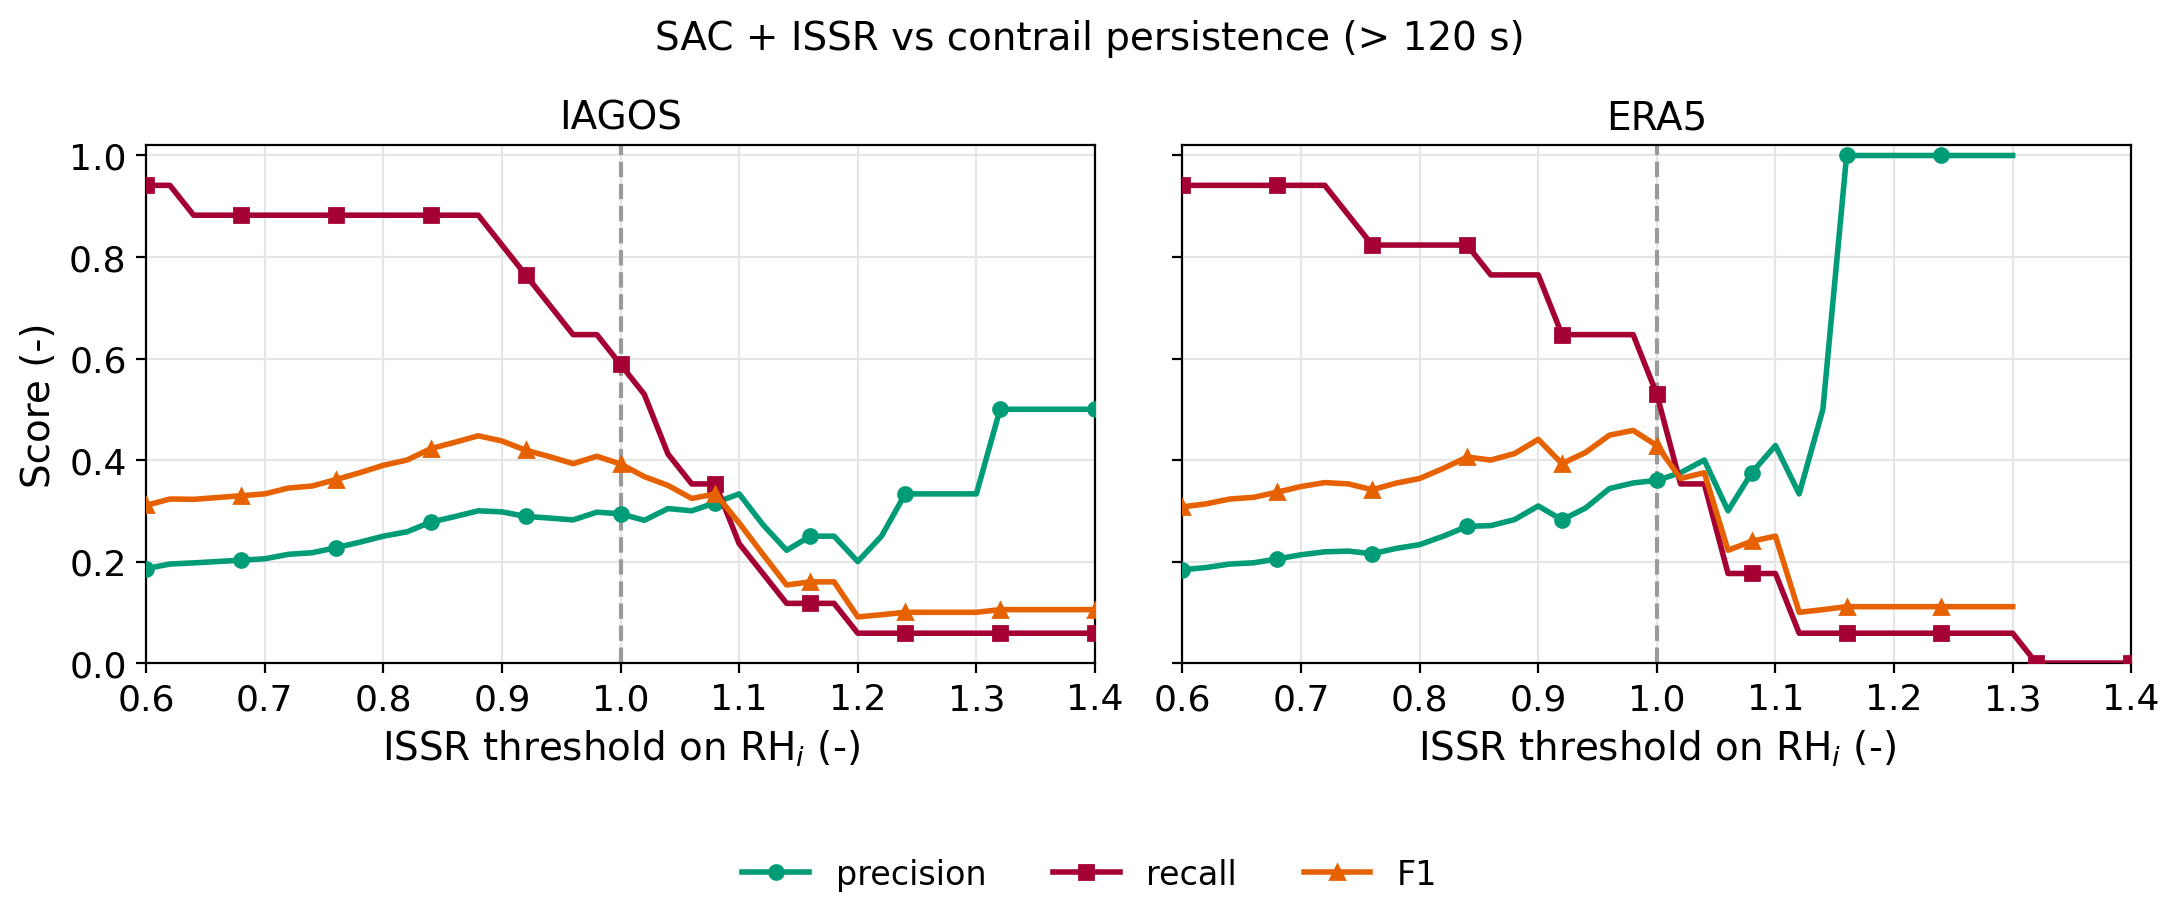

In [38]:
def sweep_issr_threshold(rhi_thresholds, persistence_threshold_s=None):
    """Metrics vs the RHi cut-off in the SAC + ISSR predictor."""
    thr_s = (PERSISTENCE_THRESHOLD_S if persistence_threshold_s is None
             else persistence_threshold_s)
    observed = persistence["lifetime"].fillna(0.0) > thr_s

    rows = []
    for rhi_thr in rhi_thresholds:
        for met, sac_col, rhi_col in [("IAGOS", "SAC_PS_IAGOS", "rhi_iagos"),
                                      ("ERA5", "SAC_PS_ERA5", "rhi_era5")]:
            pred = persistence[sac_col].astype("boolean") & issr_flag(persistence[rhi_col],
                                                                     rhi_thr)
            rows.append({
                "rhi_threshold": rhi_thr,
                "Met": met,
                **contingency(pred, observed),
            })
    return pd.DataFrame(rows)


rhi_thresholds = np.round(np.arange(0.6, 1.41, 0.02), 2)
issr_sweep = sweep_issr_threshold(rhi_thresholds)

plot_sweep(
    issr_sweep,
    x_col="rhi_threshold",
    x_label=r"ISSR threshold on RH$_i$ (-)",
    suptitle=f"SAC + ISSR vs contrail persistence (> {PERSISTENCE_THRESHOLD_S:g} s)",
    ref_lines=[(1.0, "--", "")],
    markevery=4,
)

In [39]:
issr_candidates = [0.8, 0.9, 0.95, 1.0, 1.05, 1.1, 1.2]
issr_table = sweep_issr_threshold(issr_candidates)

side_by_side(issr_table, ["rhi_threshold"]).round(DECIMALS)

IAGOS                                                    ERA5  \
                 TP    FP    FN     TN precision recall     F1    ETS    TP   
rhi_threshold                                                                 
0.80           15.0  45.0   2.0  304.0     0.250  0.882  0.390  0.206  14.0   
0.90           14.0  33.0   3.0  316.0     0.298  0.824  0.438  0.247  13.0   
0.95           11.0  30.0   6.0  319.0     0.268  0.647  0.379  0.202  11.0   
1.00           10.0  24.0   7.0  325.0     0.294  0.588  0.392  0.214   9.0   
1.05            6.0  14.0  11.0  335.0     0.300  0.353  0.324  0.169   5.0   
1.10            4.0   8.0  13.0  341.0     0.333  0.235  0.276  0.141   3.0   
1.20            1.0   4.0  16.0  345.0     0.200  0.059  0.091  0.037   1.0   

                                                                 
                 FP    FN     TN precision recall     F1    ETS  
rhi_threshold                                                    
0.80           46.0   3.0  303.0     0.233  0.824  0.364  0.186  
0.90           29.0   4.0  320.0     0.310  0.765  0.441  0.251  
0.95           22.0   6.0  327.0     0.333  0.647  0.440  0.253  
1.00           16.0   8.0  333.0     0.360  0.529  0.429  0.246  
1.05            8.0  12.0  341.0     0.385  0.294  0.333  0.180  
1.10            4.0  14.0  345.0     0.429  0.176  0.250  0.129  
1.20            0.0  16.0  349.0     1.000  0.059  0.111  0.056

In [40]:
best_issr = (
    issr_sweep.dropna(subset=["F1"])
    .sort_values("F1", ascending=False)
    .groupby("Met")
    .head(1)
    .sort_values("Met")
)
print(f"RHi threshold maximising F1 (persistence > {PERSISTENCE_THRESHOLD_S:g} s):")
print(best_issr[["Met", "rhi_threshold", "TP", "FP", "FN", "TN",
                 "precision", "recall", "F1", "ETS"]].round(DECIMALS).to_string(index=False))

RHi threshold maximising F1 (persistence > 120 s):
  Met  rhi_threshold  TP  FP  FN  TN  precision  recall    F1   ETS
 ERA5           0.98  11  20   6 329      0.355   0.647 0.458 0.269
IAGOS           0.88  15  35   2 314      0.300   0.882 0.448 0.255
